# Sleep Stage Classification — Advanced Ensemble Learning
**Author:** Anish  
**Notebook:** `notebooks/ensemble_Anish.ipynb`  
**Output:** `outputs/ensemble_predictions.csv`  

### Architecture Overview
1. **In-Memory Temporal Context Augmentation:** Expands the 12 frozen features with bi-directional leads/lags ($\pm 1, \pm 2$ epochs) and centered rolling windows (15 epochs = 7.5 mins) per subject without modifying `frozen/`.
2. **Level-1 Subject-Grouped OOF Stacking:** 5-fold `StratifiedGroupKFold` grouped by `subject` to prevent data leakage across patients, combining **LightGBM**, **XGBoost**, **CatBoost**, and **ExtraTrees** with blended class-balanced sample weights.
3. **Level-2 Meta-Learner & Temporal Smoothing:** Regularized Logistic Regression meta-classifier trained on Out-Of-Fold (OOF) probability distributions + rolling probability context, followed by Gaussian-like centered temporal smoothing.
4. **Standardized Output Export:** Saves final predictions and class probabilities to `outputs/ensemble_predictions.csv`.

In [1]:
# 1. Mount Google Drive & Install Dependencies
from google.colab import drive
drive.mount('/content/drive')

!pip install -q lightgbm xgboost catboost scikit-learn pyarrow

Mounted at /content/drive


In [2]:
# 2. Imports & Directory Configuration
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score, f1_score, cohen_kappa_score,
    classification_report, confusion_matrix
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.utils.class_weight import compute_sample_weight

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)

# Folder paths matching team structure
BASE_DIR = "/content/drive/MyDrive/Colab Notebooks/ColabData"
FROZEN_DIR = os.path.join(BASE_DIR, "frozen")
OUTPUT_DIR = os.path.join(BASE_DIR, "outputs")
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [3]:
# 3. Load Frozen Data (Read-Only) & Verify Schema
train_df = pd.read_parquet(os.path.join(FROZEN_DIR, "train_final.parquet"))
test_df = pd.read_parquet(os.path.join(FROZEN_DIR, "test_final.parquet"))

with open(os.path.join(FROZEN_DIR, "feature_cols_final.json"), "r") as f:
    base_features = json.load(f)

print(f"Train shape: {train_df.shape} | Unique Subjects: {train_df['subject'].nunique()}")
print(f"Test shape:  {test_df.shape}  | Unique Subjects: {test_df['subject'].nunique()}")
print(f"Frozen Features ({len(base_features)}): {base_features}")

# Canonical sleep stage mapping
STAGE_ORDER = ["Wake", "N1", "N2", "N3", "REM"]
STAGE_TO_IDX = {stage: idx for idx, stage in enumerate(STAGE_ORDER)}
IDX_TO_STAGE = {idx: stage for idx, stage in enumerate(STAGE_ORDER)}

# Ensure chronological ordering within each subject
train_df = train_df.sort_values(["subject", "time"]).reset_index(drop=True)
test_df = test_df.sort_values(["subject", "time"]).reset_index(drop=True)

y_train = train_df["stage_label"].map(STAGE_TO_IDX).values
y_test = test_df["stage_label"].map(STAGE_TO_IDX).values
groups_train = train_df["subject"].values

Train shape: (19501, 24) | Unique Subjects: 24
Test shape:  (6007, 24)  | Unique Subjects: 7
Frozen Features (12): ['acc_mean', 'acc_std', 'hr_mean_clipped_roll5_mean', 'hr_mean_clipped_roll5_std', 'acc_mean_roll5_mean', 'acc_mean_roll5_std', 'hr_delta', 'acc_delta', 'hr_mean_clipped_subj_z', 'acc_mean_subj_z', 'steps_roll5_sum', 'night_position']


In [4]:
# 4. In-Memory Temporal Context Engineering (Leads, Lags & Multi-Scale Windows)
def add_temporal_context(df, feature_cols):
    df = df.sort_values(["subject", "time"]).copy()
    new_cols = []

    core_signals = [
        "acc_mean", "acc_std", "hr_mean_clipped_roll5_mean",
        "hr_mean_clipped_subj_z", "acc_mean_subj_z", "hr_delta"
    ]

    for col in core_signals:
        # Bi-directional leads & lags (-2, -1, +1, +2 epochs -> +/- 60s context)
        for shift in [-2, -1, 1, 2]:
            col_name = f"{col}_shift_{shift}"
            df[col_name] = df.groupby("subject")[col].shift(shift)
            new_cols.append(col_name)

        # Wider centered rolling window (15 epochs = 7.5 minutes)
        roll15_mean = f"{col}_roll15_mean"
        roll15_std = f"{col}_roll15_std"
        df[roll15_mean] = df.groupby("subject")[col].transform(
            lambda x: x.rolling(15, min_periods=1, center=True).mean()
        )
        df[roll15_std] = df.groupby("subject")[col].transform(
            lambda x: x.rolling(15, min_periods=1, center=True).std().fillna(0)
        )
        new_cols.extend([roll15_mean, roll15_std])

    # Physiological autonomic-to-motor interaction ratio
    df["hr_to_acc_ratio"] = df["hr_mean_clipped_roll5_mean"] / (df["acc_mean_roll5_mean"] + 1e-5)
    new_cols.append("hr_to_acc_ratio")

    all_features = feature_cols + new_cols
    df[all_features] = df.groupby("subject")[all_features].transform(
        lambda x: x.bfill().ffill()
    ).fillna(0)

    return df, all_features

train_aug, ensemble_features = add_temporal_context(train_df, base_features)
test_aug, _ = add_temporal_context(test_df, base_features)

X_train = train_aug[ensemble_features].values
X_test = test_aug[ensemble_features].values

print(f"Expanded feature count for Advanced Ensemble: {len(ensemble_features)}")

Expanded feature count for Advanced Ensemble: 49


In [5]:
# 5. Level-1 Base Learners: 5-Fold Subject-Grouped Out-Of-Fold (OOF) Stacking
N_FOLDS = 5
N_CLASSES = len(STAGE_ORDER)
sgkf = StratifiedGroupKFold(n_splits=N_FOLDS)

oof_preds = {
    "lgb": np.zeros((len(train_aug), N_CLASSES)),
    "xgb": np.zeros((len(train_aug), N_CLASSES)),
    "cat": np.zeros((len(train_aug), N_CLASSES)),
    "et":  np.zeros((len(train_aug), N_CLASSES)),
}

test_preds = {
    "lgb": np.zeros((len(test_aug), N_CLASSES)),
    "xgb": np.zeros((len(test_aug), N_CLASSES)),
    "cat": np.zeros((len(test_aug), N_CLASSES)),
    "et":  np.zeros((len(test_aug), N_CLASSES)),
}

print("Starting 5-Fold Subject-Grouped Cross-Validation...\n")

for fold, (train_idx, val_idx) in enumerate(sgkf.split(X_train, y_train, groups_train)):
    X_tr, y_tr = X_train[train_idx], y_train[train_idx]
    X_va, y_va = X_train[val_idx], y_train[val_idx]

    # Softened balanced sample weights to boost minority stages (N1, Wake) without tanking overall accuracy
    sample_weights = compute_sample_weight("balanced", y_tr)
    blended_weights = 0.5 * sample_weights + 0.5 * np.ones_like(sample_weights)

    # --- Model 1: LightGBM ---
    model_lgb = lgb.LGBMClassifier(
        n_estimators=1000,
        learning_rate=0.03,
        num_leaves=31,
        colsample_bytree=0.8,
        subsample=0.8,
        random_state=SEED + fold,
        n_jobs=-1,
        verbose=-1
    )
    model_lgb.fit(
        X_tr, y_tr,
        sample_weight=blended_weights,
        eval_set=[(X_va, y_va)],
        callbacks=[lgb.early_stopping(50, verbose=False)]
    )
    oof_preds["lgb"][val_idx] = model_lgb.predict_proba(X_va)
    test_preds["lgb"] += model_lgb.predict_proba(X_test) / N_FOLDS

    # --- Model 2: XGBoost ---
    model_xgb = xgb.XGBClassifier(
        n_estimators=1000,
        learning_rate=0.03,
        max_depth=6,
        colsample_bytree=0.8,
        subsample=0.8,
        eval_metric="mlogloss",
        early_stopping_rounds=50,
        random_state=SEED + fold,
        n_jobs=-1
    )
    model_xgb.fit(
        X_tr, y_tr,
        sample_weight=blended_weights,
        eval_set=[(X_va, y_va)],
        verbose=False
    )
    oof_preds["xgb"][val_idx] = model_xgb.predict_proba(X_va)
    test_preds["xgb"] += model_xgb.predict_proba(X_test) / N_FOLDS

    # --- Model 3: CatBoost ---
    model_cat = CatBoostClassifier(
        iterations=1000,
        learning_rate=0.04,
        depth=6,
        loss_function="MultiClass",
        random_seed=SEED + fold,
        verbose=False
    )
    model_cat.fit(
        X_tr, y_tr,
        sample_weight=blended_weights,
        eval_set=(X_va, y_va),
        early_stopping_rounds=50,
        verbose=False
    )
    oof_preds["cat"][val_idx] = model_cat.predict_proba(X_va)
    test_preds["cat"] += model_cat.predict_proba(X_test) / N_FOLDS

    # --- Model 4: ExtraTrees ---
    model_et = ExtraTreesClassifier(
        n_estimators=300,
        max_depth=16,
        min_samples_leaf=4,
        class_weight="balanced_subsample",
        random_state=SEED + fold,
        n_jobs=-1
    )
    model_et.fit(X_tr, y_tr)
    oof_preds["et"][val_idx] = model_et.predict_proba(X_va)
    test_preds["et"] += model_et.predict_proba(X_test) / N_FOLDS

    fold_f1 = f1_score(y_va, oof_preds["lgb"][val_idx].argmax(axis=1), average="macro")
    print(f"Fold {fold + 1}/{N_FOLDS} finished | Val Subjects: {np.unique(groups_train[val_idx])[:3]}... | LGB Macro-F1: {fold_f1:.4f}")

print("\n--- Out-Of-Fold Base Model Performance ---")
for name in oof_preds:
    preds = oof_preds[name].argmax(axis=1)
    acc = accuracy_score(y_train, preds)
    mf1 = f1_score(y_train, preds, average="macro")
    kappa = cohen_kappa_score(y_train, preds)
    print(f"{name.upper():<4} | Accuracy: {acc:.4f} | Macro-F1: {mf1:.4f} | Kappa: {kappa:.4f}")

Starting 5-Fold Subject-Grouped Cross-Validation...

Fold 1/5 finished | Val Subjects: ['1455390' '2598705' '5383425']... | LGB Macro-F1: 0.4256
Fold 2/5 finished | Val Subjects: ['1360686' '2638030' '9106476']... | LGB Macro-F1: 0.4946
Fold 3/5 finished | Val Subjects: ['1818471' '4426783' '46343']... | LGB Macro-F1: 0.5364
Fold 4/5 finished | Val Subjects: ['1066528' '4314139' '8000685']... | LGB Macro-F1: 0.5285
Fold 5/5 finished | Val Subjects: ['1449548' '3509524' '5132496']... | LGB Macro-F1: 0.5091

--- Out-Of-Fold Base Model Performance ---
LGB  | Accuracy: 0.5959 | Macro-F1: 0.5025 | Kappa: 0.3888
XGB  | Accuracy: 0.6003 | Macro-F1: 0.5073 | Kappa: 0.3947
CAT  | Accuracy: 0.6090 | Macro-F1: 0.5237 | Kappa: 0.4155
ET   | Accuracy: 0.5666 | Macro-F1: 0.4938 | Kappa: 0.3812


In [6]:
# 6. Level-2 Meta-Learner & Temporal Probability Smoothing
def build_meta_features(pred_dict, df_ref):
    raw_probs = np.hstack([pred_dict["lgb"], pred_dict["xgb"], pred_dict["cat"], pred_dict["et"]])
    prob_df = pd.DataFrame(raw_probs, index=df_ref.index)
    prob_df["subject"] = df_ref["subject"].values

    # Rolling 5-epoch centered probability average per subject
    smoothed_probs = prob_df.groupby("subject").transform(
        lambda x: x.rolling(5, min_periods=1, center=True).mean()
    ).values

    return np.hstack([raw_probs, smoothed_probs])

X_meta_train = build_meta_features(oof_preds, train_aug)
X_meta_test = build_meta_features(test_preds, test_aug)

# Train Level-2 Logistic Regression Meta-Learner
meta_learner = LogisticRegression(C=0.5, max_iter=1000, random_state=SEED)
meta_learner.fit(X_meta_train, y_train)

raw_test_meta_probs = meta_learner.predict_proba(X_meta_test)

# Post-Processing: Final temporal smoothing on test probabilities per subject
test_prob_df = pd.DataFrame(raw_test_meta_probs, columns=[f"prob_{s}" for s in STAGE_ORDER])
test_prob_df["subject"] = test_aug["subject"].values

smoothed_test_probs = test_prob_df.groupby("subject").transform(
    lambda x: x.rolling(5, min_periods=1, center=True).mean()
).values

final_test_preds = smoothed_test_probs.argmax(axis=1)

=== FINAL ADVANCED ENSEMBLE TEST SET METRICS ===
Accuracy:      0.6149
Macro F1:      0.4850
Weighted F1:   0.5893
Cohen's Kappa: 0.4097

              precision    recall  f1-score   support

        Wake     0.6186    0.4733    0.5363       562
          N1     0.2353    0.0408    0.0696       392
          N2     0.6012    0.7811    0.6794      2768
          N3     0.6950    0.3659    0.4794       984
         REM     0.6380    0.6841    0.6602      1301

    accuracy                         0.6149      6007
   macro avg     0.5576    0.4690    0.4850      6007
weighted avg     0.6023    0.6149    0.5893      6007



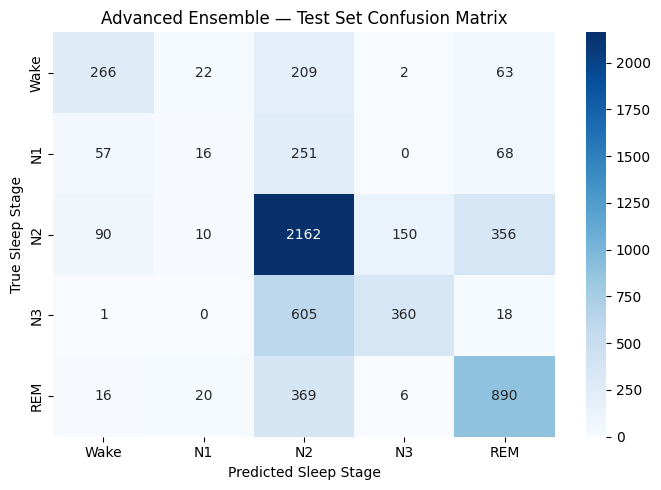

In [7]:
# 7. Final Evaluation & Confusion Matrix
print("=== FINAL ADVANCED ENSEMBLE TEST SET METRICS ===")
print(f"Accuracy:      {accuracy_score(y_test, final_test_preds):.4f}")
print(f"Macro F1:      {f1_score(y_test, final_test_preds, average='macro'):.4f}")
print(f"Weighted F1:   {f1_score(y_test, final_test_preds, average='weighted'):.4f}")
print(f"Cohen's Kappa: {cohen_kappa_score(y_test, final_test_preds):.4f}\n")

print(classification_report(y_test, final_test_preds, target_names=STAGE_ORDER, digits=4))

cm = confusion_matrix(y_test, final_test_preds)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=STAGE_ORDER, yticklabels=STAGE_ORDER)
plt.title("Advanced Ensemble — Test Set Confusion Matrix")
plt.xlabel("Predicted Sleep Stage")
plt.ylabel("True Sleep Stage")
plt.tight_layout()
plt.show()

In [8]:
# 8. Export Predictions to outputs/ensemble_predictions.csv
output_df = pd.DataFrame({
    "subject": test_aug["subject"].values,
    "time": test_aug["time"].values,
    "true_stage": test_aug["stage"].values,
    "true_stage_label": test_aug["stage_label"].values,
    "pred_stage_idx": final_test_preds,
    "pred_stage_label": [IDX_TO_STAGE[idx] for idx in final_test_preds],
})

for idx, stage_name in enumerate(STAGE_ORDER):
    output_df[f"prob_{stage_name}"] = smoothed_test_probs[:, idx]

output_file = os.path.join(OUTPUT_DIR, "ensemble_predictions.csv")
output_df.to_csv(output_file, index=False)

print(f"Successfully saved predictions to: {output_file}")
output_df.head(10)

Successfully saved predictions to: /content/drive/MyDrive/Colab Notebooks/ColabData/outputs/ensemble_predictions.csv


,subject,time,true_stage,true_stage_label,pred_stage_idx,pred_stage_label,prob_Wake,prob_N1,prob_N2,prob_N3,prob_REM
0,3997827,510,0,Wake,0,Wake,0.895945,0.070304,0.017191,0.007655,0.008904
1,3997827,540,0,Wake,0,Wake,0.897608,0.069550,0.016614,0.007530,0.008699
2,3997827,570,0,Wake,0,Wake,0.900811,0.067316,0.016049,0.007366,0.008458
3,3997827,600,0,Wake,0,Wake,0.901448,0.067698,0.015483,0.006980,0.008391
4,3997827,630,0,Wake,0,Wake,0.897605,0.070257,0.016363,0.006886,0.008889
5,3997827,660,0,Wake,0,Wake,0.892237,0.073598,0.017768,0.006752,0.009645
6,3997827,690,0,Wake,0,Wake,0.892808,0.072647,0.018175,0.006588,0.009781
7,3997827,720,0,Wake,0,Wake,0.890798,0.073993,0.018785,0.006330,0.010094
8,3997827,750,0,Wake,0,Wake,0.885808,0.076882,0.020353,0.006100,0.010858
9,3997827,780,0,Wake,0,Wake,0.875760,0.082709,0.023398,0.005735,0.012398
